# Artificial Intelligence Coursework  
## London Taxi Search Agent  

**Module Code:** CMP-N206-0  

**Student Name:** Farhan Ahmed Sahol  
**Student ID:** A00027052


## Overview
This notebook presents a road-based taxi routing environment inspired by selected East London locations.  
The task is modelled as a search problem in which a taxi agent must:
- start from a given road location
- navigate to a passenger pickup point
- then travel to the passenger's destination

The environment includes:
- landmarks such as Mosque, Office, Barking Station, and Home
- road nodes that define valid movement
- normal, mild-traffic, and heavy-traffic roads
- blocked locations that simulate closures or inaccessible areas

The notebook compares four search strategies:
- Breadth-First Search (BFS)
- Depth-First Search (DFS)
- Greedy Best-First Search
- A* Search

Each method is tested across multiple scenarios to evaluate path quality, road conditions, and adaptability.

In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from collections import deque
import heapq
import pandas as pd
import math

## 1. Environment Definition

The environment is represented as a discrete grid.  
Only the specified road nodes are driveable by the taxi.

### Landmarks
The environment includes four important landmarks:
- Mosque (Whitechapel Road)
- Office (1 Dock Road)
- Barking Station (Longbridge Road)
- Home (Dagenham)

### Road Conditions
Roads may have different conditions:
- normal road
- mild traffic
- heavy traffic
- blocked road

Blocked positions may also be placed outside the road network for visual realism, although the most meaningful blocked positions are usually those placed directly on road nodes.

In [2]:
# 1. GRID CONFIGURATION
GRID_SIZE = 17

# 2. LANDMARKS
landmarks = {
    "Mosque\n(Whitechapel Road)": (9, 0),
    "Office\n(1 Dock Road)": (12, 5),
    "Barking Station\n(Longbridge Road)": (9, 10),
    "Home\n(Dagenham)": (8, 14),
}

# Short landmark lookup for scenarios
landmark_points = {
    "Mosque": (9, 0),
    "Office": (12, 5),
    "Barking": (9, 10),
    "Home": (8, 14),
}

# 3. ROAD NODES
road_nodes = [
    (9,0),    # Mosque
    (12,5),   # Office
    (9,10),   # Barking
    (8,14),   # Home

    # Mosque side corridor
    (10,0), (11,0), (11,1), (11,2),
    (10,1), (9,1), (9,2), (9,3), (10,3),

    # Connect toward office
    (10,4), (10,5), (11,5), (12,5),

    # Office to central corridor
    (11,6), (10,6), (10,7), (10,8), (10,9), (10,10),

    # Vertical links around Barking
    (9,8), (9,9), (9,10),
    (11,9), (12,10),

    # Toward home
    (10,11), (10,12), (10,13), (10,14),
    (9,12), (9,13), (9,14),
    (8,10), (8,11), (8,12), (8,13), (8,14),

    # Lower optional connectors
    (13,5), (13,6), (13,7), (13,8),
    (14,6), (14,7), (14,8), (14,9), (14,10), (14,11),
]


road_nodes = list(dict.fromkeys(road_nodes))
road_node_set = set(road_nodes)

# 4. ROAD LABELS
road_labels = {
    (10,0): "C St Rd",
    (11,1): "The Hwy",
    (9,1): "Mile End Rd",
    (10,3): "Commercial Rd",
    (9,3): "Blackwall Tunnel",
    (11,6): "Silvertown Way",
    (10,6): "S Way",
    (10,7): "A13",
    (9,8): "N Circular Rd",
    (11,9): "Victoria Dock Rd",
    (12,10): "Connaught Rd Bridge",
    (8,10): "Longbridge Rd",
    (10,12): "A13",
    (9,13): "Porters Avenue",
    (8,13): "Becontree Avenue",
    (14,6): "N Woolich Rd",
    (14,11): "S Way",
}

## 2. Traffic and Blocked Road Model

The environment includes three road cost categories:

- Normal road: cost 1
- Mild traffic: cost 3
- Heavy traffic: cost 6

Blocked roads are treated as impassable.

This allows the notebook to compare search methods in both unweighted and weighted routing conditions.

In [3]:
# 5. DEFAULT TRAFFIC / BLOCKED CONFIGURATION

default_mild_traffic_roads = {
    (10,6),   # Silvertown / S Way side
    (10,7),   # A13 segment
    (9,13),   # Porters Avenue
}

default_heavy_traffic_roads = {
    (10,10),  # central A13 side
    (10,12),  # A13 link
}

default_blocked_positions = {
    (7, 9),    # off-road example
    (12, 12),  # off-road example
}

def get_road_cost(position, mild_traffic, heavy_traffic, blocked):
    """
    Return movement cost for a position.
    """
    if position in blocked:
        return math.inf
    if position in heavy_traffic:
        return 6
    if position in mild_traffic:
        return 3
    if position in road_node_set:
        return 1
    return math.inf

## 3. Helper Functions

The following helper functions support:
- movement validation
- neighbor generation
- heuristic calculation
- path reconstruction
- plotting

In [4]:
def in_bounds(position):
    r, c = position
    return 0 <= r < GRID_SIZE and 0 <= c < GRID_SIZE

def is_driveable(position, blocked):
    return in_bounds(position) and position in road_node_set and position not in blocked

def get_neighbors(position, blocked):
    r, c = position
    candidate_moves = [
        (r - 1, c),
        (r + 1, c),
        (r, c - 1),
        (r, c + 1)
    ]
    return [p for p in candidate_moves if is_driveable(p, blocked)]

def heuristic(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def reconstruct_path(came_from, start, goal):
    if goal == start:
        return [start]
    if goal not in came_from:
        return []

    path = [goal]
    current = goal
    while current != start:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

def split_roads_by_condition(all_roads, mild, heavy, blocked):
    return [
        node for node in all_roads
        if node not in mild and node not in heavy and node not in blocked
    ]

def draw_text_label(ax, row, col, text, dx=0.18, dy=0.38, size=7, align="left"):
    ax.text(
        col + dx,
        row + dy,
        text,
        fontsize=size,
        ha=align,
        va="center",
        bbox=dict(facecolor="white", alpha=0.95, edgecolor="lightgray", pad=1.0)
    )

## 4. Search Algorithms

Four search strategies are implemented:

### BFS
Breadth-First Search (BFS) explores a grid level by level and guarantees the shortest path when all moves have equal cost.
In the London Taxi environment, it finds the shortest route without considering traffic, so it may pass through congested areas.
It uses a queue to process nodes in first-in, first-out (FIFO) order.

### DFS
Depth-First Search (DFS) explores a grid by going as deep as possible along one path before backtracking. It does not guarantee the shortest path.
In the London Taxi environment, DFS may find a route quickly, but it can be inefficient and may take longer or indirect paths.
It uses a stack (LIFO) to process nodes.

### Greedy Best-First Search
Greedy Best-First Search selects nodes based only on the heuristic, aiming to reach the goal as quickly as possible. It does not guarantee the shortest path.In the London Taxi environment, it can find routes quickly but may choose inefficient paths by ignoring actual travel costs.It uses a priority queue based on heuristic values.

### A*
A* Search is an informed algorithm that uses both path cost and a heuristic to find the most efficient route. It guarantees the shortest path when the heuristic is accurate.In the London Taxi environment, A* can avoid congested areas and find optimal routes by considering distance and traffic costs.
It uses a priority queue to select the lowest-cost node.

In [5]:
def plot_environment(
    title,
    taxi_position=None,
    passenger_positions=None,
    destination_positions=None,
    mild_traffic_roads=None,
    heavy_traffic_roads=None,
    blocked_positions=None,
    path=None
):
    if passenger_positions is None:
        passenger_positions = []
    if destination_positions is None:
        destination_positions = []
    if mild_traffic_roads is None:
        mild_traffic_roads = set()
    if heavy_traffic_roads is None:
        heavy_traffic_roads = set()
    if blocked_positions is None:
        blocked_positions = set()
    if path is None:
        path = []

    fig, ax = plt.subplots(figsize=(12, 10))

    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    ax.grid(True, color="lightgray", linewidth=1, alpha=0.7)

    normal_roads = split_roads_by_condition(
        road_nodes, mild_traffic_roads, heavy_traffic_roads, blocked_positions
    )

    if normal_roads:
        x = [c for r, c in normal_roads]
        y = [r for r, c in normal_roads]
        ax.scatter(x, y, s=85, c="black", marker="o")

    if mild_traffic_roads:
        x = [c for r, c in mild_traffic_roads]
        y = [r for r, c in mild_traffic_roads]
        ax.scatter(x, y, s=95, c="orange", marker="o", edgecolors="black", linewidths=0.8)

    if heavy_traffic_roads:
        x = [c for r, c in heavy_traffic_roads]
        y = [r for r, c in heavy_traffic_roads]
        ax.scatter(x, y, s=100, c="red", marker="o", edgecolors="black", linewidths=0.8)

    if blocked_positions:
        x = [c for r, c in blocked_positions]
        y = [r for r, c in blocked_positions]
        ax.scatter(x, y, s=180, c="red", marker="^", edgecolors="black", linewidths=1.0)

    # draw path
    if path:
        path_x = [c for r, c in path]
        path_y = [r for r, c in path]
        ax.plot(path_x, path_y, linewidth=3, color="royalblue", alpha=0.85)

    # landmarks
    for label, (r, c) in landmarks.items():
        ax.scatter(c, r, s=500, c="limegreen", marker="*", edgecolors="black", linewidths=1.1)
        ax.text(
            c + 0.22,
            r + 0.10,
            label,
            fontsize=9,
            ha="left",
            va="center",
            bbox=dict(facecolor="white", alpha=0.95, edgecolor="none", pad=1.4)
        )

    if taxi_position is not None:
        r, c = taxi_position
        ax.scatter(c, r, s=280, c="royalblue", marker="p", edgecolors="black", linewidths=1.0)

    if passenger_positions:
        x = [c for r, c in passenger_positions]
        y = [r for r, c in passenger_positions]
        ax.scatter(x, y, s=180, c="plum", marker="D", edgecolors="black", linewidths=1.0)

    for r, c in destination_positions:
        ax.text(c, r, "❤", fontsize=22, color="red", ha="center", va="center")

    for (r, c), text in road_labels.items():
        draw_text_label(ax, r, c, text)

    legend_items = [
        Line2D([0], [0], marker='*', color='w', label='Landmark',
               markerfacecolor='limegreen', markeredgecolor='black', markersize=16),
        Line2D([0], [0], marker='o', color='w', label='Normal Road',
               markerfacecolor='black', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Mild Traffic',
               markerfacecolor='orange', markeredgecolor='black', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Heavy Traffic',
               markerfacecolor='red', markeredgecolor='black', markersize=10),
        Line2D([0], [0], marker='^', color='w', label='Blocked',
               markerfacecolor='red', markeredgecolor='black', markersize=11),
        Line2D([0], [0], marker='D', color='w', label='Passenger',
               markerfacecolor='plum', markeredgecolor='black', markersize=10),
        Line2D([0], [0], marker='p', color='w', label='Taxi',
               markerfacecolor='royalblue', markeredgecolor='black', markersize=12),
        Line2D([0], [0], marker='$❤$', color='w', label='Destination',
               markersize=14),
    ]
    ax.legend(handles=legend_items, loc="upper right")

    ax.set_title(title, fontsize=15)
    ax.set_xlabel("Grid Columns")
    ax.set_ylabel("Grid Rows")
    plt.tight_layout()
    plt.show()

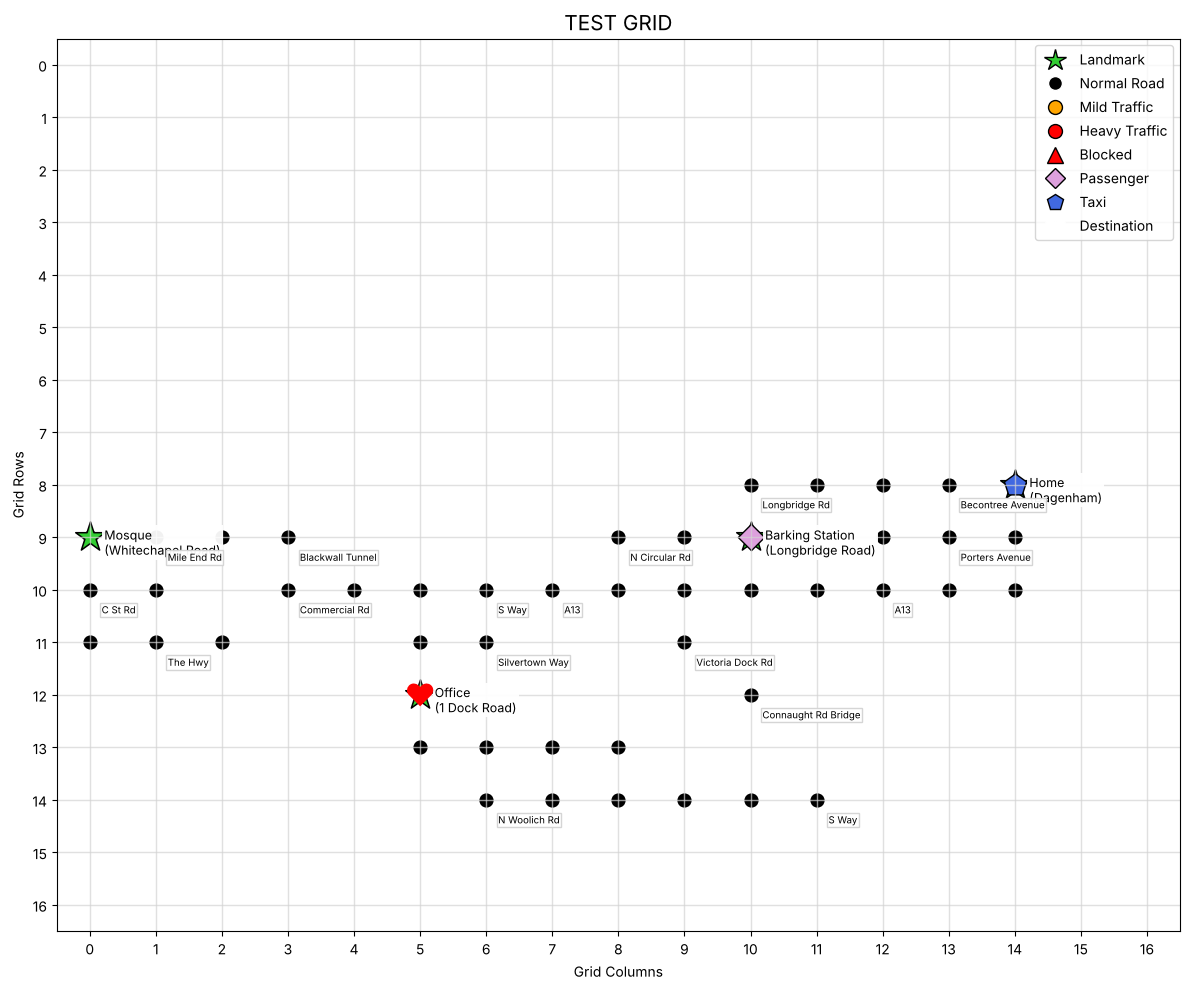

In [6]:
plot_environment(
    title="TEST GRID",
    taxi_position=landmark_points["Home"],
    passenger_positions=[landmark_points["Barking"]],
    destination_positions=[landmark_points["Office"]],
    mild_traffic_roads=set(),
    heavy_traffic_roads=set(),
    blocked_positions=set()
)

In [7]:
def plot_scenario_with_all_algorithms(scenario_name, scenario_data):
    """
    Plot one scenario and overlay the paths found by
    BFS, DFS, Greedy, and A* using different colors.
    """
    start = scenario_data["taxi_start"]
    passenger = scenario_data["passenger"]
    destination = scenario_data["destination"]
    blocked = scenario_data["blocked"]
    mild_traffic = scenario_data["mild_traffic"]
    heavy_traffic = scenario_data["heavy_traffic"]

    algorithm_colors = {
        "BFS": "royalblue",
        "DFS": "purple",
        "Greedy": "green",
        "A*": "orange"
    }

    fig, ax = plt.subplots(figsize=(12, 10))

    # Grid
    ax.set_xlim(-0.5, GRID_SIZE - 0.5)
    ax.set_ylim(GRID_SIZE - 0.5, -0.5)
    ax.set_xticks(range(GRID_SIZE))
    ax.set_yticks(range(GRID_SIZE))
    ax.grid(True, color="lightgray", linewidth=1, alpha=0.7)

    # Roads
    normal_roads = split_roads_by_condition(
        road_nodes, mild_traffic, heavy_traffic, blocked
    )

    if normal_roads:
        x = [c for r, c in normal_roads]
        y = [r for r, c in normal_roads]
        ax.scatter(x, y, s=85, c="black", marker="o")

    if mild_traffic:
        x = [c for r, c in mild_traffic]
        y = [r for r, c in mild_traffic]
        ax.scatter(x, y, s=95, c="orange", marker="o", edgecolors="black", linewidths=0.8)

    if heavy_traffic:
        x = [c for r, c in heavy_traffic]
        y = [r for r, c in heavy_traffic]
        ax.scatter(x, y, s=100, c="red", marker="o", edgecolors="black", linewidths=0.8)

    if blocked:
        x = [c for r, c in blocked]
        y = [r for r, c in blocked]
        ax.scatter(x, y, s=180, c="red", marker="^", edgecolors="black", linewidths=1.0)

    # Landmarks
    for label, (r, c) in landmarks.items():
        ax.scatter(c, r, s=500, c="limegreen", marker="*", edgecolors="black", linewidths=1.1)
        ax.text(
            c + 0.22,
            r + 0.10,
            label,
            fontsize=9,
            ha="left",
            va="center",
            bbox=dict(facecolor="white", alpha=0.95, edgecolor="none", pad=1.4)
        )

    # Taxi, passenger, destination
    ax.scatter(start[1], start[0], s=280, c="royalblue", marker="p", edgecolors="black", linewidths=1.0)
    ax.scatter(passenger[1], passenger[0], s=180, c="plum", marker="D", edgecolors="black", linewidths=1.0)
    ax.text(destination[1], destination[0], "❤", fontsize=22, color="red", ha="center", va="center")

    # Road labels
    for (r, c), text in road_labels.items():
        draw_text_label(ax, r, c, text)

    # Run all algorithms and plot paths
    for algorithm, color in algorithm_colors.items():
        phase1 = run_search(algorithm, start, passenger, mild_traffic, heavy_traffic, blocked)
        phase2 = run_search(algorithm, passenger, destination, mild_traffic, heavy_traffic, blocked)

        if phase1["success"] and phase2["success"]:
            path1 = phase1["path"]
            path2 = phase2["path"]
            full_path = path1 + path2[1:] if len(path2) > 1 else path1

            path_x = [c for r, c in full_path]
            path_y = [r for r, c in full_path]
            ax.plot(path_x, path_y, linewidth=3, color=color, alpha=0.9, label=f"{algorithm} Path")

    # Legend
    legend_items = [
        Line2D([0], [0], marker='*', color='w', label='Landmark',
               markerfacecolor='limegreen', markeredgecolor='black', markersize=16),
        Line2D([0], [0], marker='o', color='w', label='Normal Road',
               markerfacecolor='black', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Mild Traffic',
               markerfacecolor='orange', markeredgecolor='black', markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Heavy Traffic',
               markerfacecolor='red', markeredgecolor='black', markersize=10),
        Line2D([0], [0], marker='^', color='w', label='Blocked',
               markerfacecolor='red', markeredgecolor='black', markersize=11),
        Line2D([0], [0], marker='D', color='w', label='Passenger',
               markerfacecolor='plum', markeredgecolor='black', markersize=10),
        Line2D([0], [0], marker='p', color='w', label='Taxi',
               markerfacecolor='royalblue', markeredgecolor='black', markersize=12),
        Line2D([0], [0], marker='$❤$', color='w', label='Destination',
               markersize=14),
        Line2D([0], [0], color='royalblue', lw=3, label='BFS Path'),
        Line2D([0], [0], color='purple', lw=3, label='DFS Path'),
        Line2D([0], [0], color='green', lw=3, label='Greedy Path'),
        Line2D([0], [0], color='orange', lw=3, label='A* Path'),
    ]

    ax.legend(handles=legend_items, loc="upper right")
    ax.set_title(f"{scenario_name}: Algorithm Path Comparison", fontsize=15)
    ax.set_xlabel("Grid Columns")
    ax.set_ylabel("Grid Rows")
    plt.tight_layout()
    plt.show()

In [8]:
def bfs_search(start, goal, blocked):
    queue = deque([start])
    visited = {start}
    came_from = {}
    nodes_explored = 0

    while queue:
        current = queue.popleft()
        nodes_explored += 1

        if current == goal:
            return {
                "path": reconstruct_path(came_from, start, goal),
                "nodes_explored": nodes_explored,
                "success": True
            }

        for neighbor in get_neighbors(current, blocked):
            if neighbor not in visited:
                visited.add(neighbor)
                came_from[neighbor] = current
                queue.append(neighbor)

    return {"path": [], "nodes_explored": nodes_explored, "success": False}


def dfs_search(start, goal, blocked):
    stack = [start]
    visited = {start}
    came_from = {}
    nodes_explored = 0

    while stack:
        current = stack.pop()
        nodes_explored += 1

        if current == goal:
            return {
                "path": reconstruct_path(came_from, start, goal),
                "nodes_explored": nodes_explored,
                "success": True
            }

        neighbors = get_neighbors(current, blocked)
        neighbors.reverse()

        for neighbor in neighbors:
            if neighbor not in visited:
                visited.add(neighbor)
                came_from[neighbor] = current
                stack.append(neighbor)

    return {"path": [], "nodes_explored": nodes_explored, "success": False}


def greedy_search(start, goal, blocked):
    frontier = []
    heapq.heappush(frontier, (heuristic(start, goal), start))
    came_from = {}
    visited = set()
    nodes_explored = 0

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        nodes_explored += 1

        if current == goal:
            return {
                "path": reconstruct_path(came_from, start, goal),
                "nodes_explored": nodes_explored,
                "success": True
            }

        for neighbor in get_neighbors(current, blocked):
            if neighbor not in visited:
                came_from[neighbor] = current
                heapq.heappush(frontier, (heuristic(neighbor, goal), neighbor))

    return {"path": [], "nodes_explored": nodes_explored, "success": False}


def astar_search(start, goal, mild_traffic, heavy_traffic, blocked):
    frontier = []
    heapq.heappush(frontier, (0, start))
    came_from = {}
    g_cost = {start: 0}
    nodes_explored = 0
    visited = set()

    while frontier:
        _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        nodes_explored += 1

        if current == goal:
            return {
                "path": reconstruct_path(came_from, start, goal),
                "nodes_explored": nodes_explored,
                "success": True,
                "cost": g_cost[current]
            }

        for neighbor in get_neighbors(current, blocked):
            step_cost = get_road_cost(neighbor, mild_traffic, heavy_traffic, blocked)
            tentative_g = g_cost[current] + step_cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                priority = tentative_g + heuristic(neighbor, goal)
                came_from[neighbor] = current
                heapq.heappush(frontier, (priority, neighbor))

    return {
        "path": [],
        "nodes_explored": nodes_explored,
        "success": False,
        "cost": math.inf
    }


def run_search(algorithm, start, goal, mild_traffic, heavy_traffic, blocked):
    if algorithm == "BFS":
        return bfs_search(start, goal, blocked)
    elif algorithm == "DFS":
        return dfs_search(start, goal, blocked)
    elif algorithm == "Greedy":
        return greedy_search(start, goal, blocked)
    elif algorithm == "A*":
        return astar_search(start, goal, mild_traffic, heavy_traffic, blocked)
    else:
        raise ValueError("Unknown algorithm")

## 5. Performance Measure

The performance measure rewards successful task completion while penalising unnecessary movement and traffic exposure.

### Base scoring
- Pickup reward: +5
- Drop-off reward: +20
- Each movement step: -1
- Failure to complete route: -20

### Traffic-aware interpretation
A* additionally considers movement cost, making it more appropriate for traffic-aware routing than BFS, DFS, or Greedy search.

In [9]:
def calculate_score(path_to_passenger, path_to_destination, success):
    if not success:
        return -20

    total_steps = (len(path_to_passenger) - 1) + (len(path_to_destination) - 1)
    score = 0
    score += 5   # pickup
    score += 20  # drop-off
    score -= total_steps
    return score

## 6. Scenario Design

Five scenarios are used to evaluate the taxi environment under different journey patterns and road conditions.

The scenarios reflect movement between:
- Home
- Office
- Mosque
- Barking Station

Scenario-specific features include:
- passenger pickup points
- destination points
- mild traffic zones
- heavy traffic zones
- blocked positions

In [10]:
scenarios = {
    "Scenario 1 - Home to Office": {
        "taxi_start": landmark_points["Home"],
        "passenger": landmark_points["Home"],
        "destination": landmark_points["Office"],

        # Light disruption
        "blocked": {(10,11)},

        "mild_traffic": {(10,6), (10,7)},
        "heavy_traffic": {(10,10)},

        "description": "Direct trip from home to office with a minor central blockage."
    },

    "Scenario 2 - Office to Mosque": {
        "taxi_start": landmark_points["Office"],
        "passenger": landmark_points["Office"],
        "destination": landmark_points["Mosque"],

        # Medium disruption
        "blocked": {(10,7), (11,9)},

        "mild_traffic": {(10,6)},
        "heavy_traffic": {(10,10)},

        "description": "Office to mosque with blocked A13 section and congestion near Victoria Dock."
    },

    "Scenario 3 - Mosque to Barking": {
        "taxi_start": landmark_points["Mosque"],
        "passenger": landmark_points["Mosque"],
        "destination": landmark_points["Barking"],

        # Forces reroute
        "blocked": {(10,8)},

        "mild_traffic": {(9,8), (10,6)},
        "heavy_traffic": {(10,10)},

        "description": "Route from mosque to Barking with blocked central connector."
    },

    "Scenario 4 - Barking to Home": {
        "taxi_start": landmark_points["Barking"],
        "passenger": landmark_points["Barking"],
        "destination": landmark_points["Home"],

        # Small disruption near destination
        "blocked": {(9,12)},

        "mild_traffic": {(9,13)},
        "heavy_traffic": {(10,12)},

        "description": "Passenger from Barking to home with congestion on eastern approach."
    },

    "Scenario 5 - Home to Mosque via Barking Pickup": {
        "taxi_start": landmark_points["Home"],
        "passenger": landmark_points["Barking"],
        "destination": landmark_points["Mosque"],
        "blocked": {(10,7), (10,11)},

        "mild_traffic": {(10,6), (9,13)},
        "heavy_traffic": {(10,10)},

        "description": "Taxi starts at home, picks up at Barking, then travels to mosque under multiple disruptions."
    }
}

## 7. Simulation Logic

Each scenario is completed in two phases:
1. taxi to passenger
2. passenger to destination

The same search method is applied in both phases.

In [11]:
def simulate_scenario(algorithm, scenario_name, scenario_data, show_map=False):
    start = scenario_data["taxi_start"]
    passenger = scenario_data["passenger"]
    destination = scenario_data["destination"]
    blocked = scenario_data["blocked"]
    mild_traffic = scenario_data["mild_traffic"]
    heavy_traffic = scenario_data["heavy_traffic"]

    # Phase 1: taxi to passenger
    phase1 = run_search(algorithm, start, passenger, mild_traffic, heavy_traffic, blocked)

    if not phase1["success"]:
        return {
            "Scenario": scenario_name,
            "Algorithm": algorithm,
            "Success": False,
            "Steps": 0,
            "Score": -20,
            "Nodes Explored": phase1["nodes_explored"],
            "Path Cost": math.inf,
            "Path Length": 0
        }

    # Phase 2: passenger to destination
    phase2 = run_search(algorithm, passenger, destination, mild_traffic, heavy_traffic, blocked)

    if not phase2["success"]:
        return {
            "Scenario": scenario_name,
            "Algorithm": algorithm,
            "Success": False,
            "Steps": 0,
            "Score": -20,
            "Nodes Explored": phase1["nodes_explored"] + phase2["nodes_explored"],
            "Path Cost": math.inf,
            "Path Length": 0
        }

    path1 = phase1["path"]
    path2 = phase2["path"]
    full_path = path1 + path2[1:] if len(path2) > 1 else path1

    steps = (len(path1) - 1) + (len(path2) - 1)
    score = calculate_score(path1, path2, True)

    # weighted path cost for reference
    total_cost = 0
    for node in full_path[1:]:
        total_cost += get_road_cost(node, mild_traffic, heavy_traffic, blocked)

    if show_map:
        plot_environment(
            title=f"{scenario_name} - {algorithm}",
            taxi_position=start,
            passenger_positions=[passenger],
            destination_positions=[destination],
            mild_traffic_roads=mild_traffic,
            heavy_traffic_roads=heavy_traffic,
            blocked_positions=blocked,
            path=full_path
        )

    return {
        "Scenario": scenario_name,
        "Algorithm": algorithm,
        "Success": True,
        "Steps": steps,
        "Score": score,
        "Nodes Explored": phase1["nodes_explored"] + phase2["nodes_explored"],
        "Path Cost": total_cost,
        "Path Length": len(full_path)
    }

## 8. Run Experiments

The following section runs all scenarios using BFS, DFS, Greedy Best-First Search, and A*.

In [12]:
algorithms = ["BFS", "DFS", "Greedy", "A*"]

results = []
for scenario_name, scenario_data in scenarios.items():
    for algorithm in algorithms:
        results.append(simulate_scenario(algorithm, scenario_name, scenario_data, show_map=False))

results_df = pd.DataFrame(results)
results_df

,Scenario,Algorithm,Success,Steps,Score,Nodes Explored,Path Cost,Path Length
0,Scenario 1 - Home to Office,BFS,True,13,12,26,22.0,14
1,Scenario 1 - Home to Office,DFS,True,17,8,21,26.0,18
2,Scenario 1 - Home to Office,Greedy,True,13,12,15,17.0,14
3,Scenario 1 - Home to Office,A*,True,13,12,24,17.0,14
4,Scenario 2 - Office to Mosque,BFS,True,8,17,22,8.0,9
5,Scenario 2 - Office to Mosque,DFS,True,8,17,15,8.0,9
6,Scenario 2 - Office to Mosque,Greedy,True,8,17,10,8.0,9
7,Scenario 2 - Office to Mosque,A*,True,8,17,10,8.0,9
8,Scenario 3 - Mosque to Barking,BFS,False,0,-20,28,inf,0
9,Scenario 3 - Mosque to Barking,DFS,False,0,-20,28,inf,0


In [13]:
results_df.sort_values(by=["Scenario", "Algorithm"]).reset_index(drop=True)

,Scenario,Algorithm,Success,Steps,Score,Nodes Explored,Path Cost,Path Length
0,Scenario 1 - Home to Office,A*,True,13,12,24,17.0,14
1,Scenario 1 - Home to Office,BFS,True,13,12,26,22.0,14
2,Scenario 1 - Home to Office,DFS,True,17,8,21,26.0,18
3,Scenario 1 - Home to Office,Greedy,True,13,12,15,17.0,14
4,Scenario 2 - Office to Mosque,A*,True,8,17,10,8.0,9
5,Scenario 2 - Office to Mosque,BFS,True,8,17,22,8.0,9
6,Scenario 2 - Office to Mosque,DFS,True,8,17,15,8.0,9
7,Scenario 2 - Office to Mosque,Greedy,True,8,17,10,8.0,9
8,Scenario 3 - Mosque to Barking,A*,False,0,-20,28,inf,0
9,Scenario 3 - Mosque to Barking,BFS,False,0,-20,28,inf,0


## 9. Visual Comparison of Search Methods

The following figures display the same scenario under four different search methods:
BFS, DFS, Greedy Best-First Search, and A*.  
This allows direct visual comparison of route choice under the same road conditions.

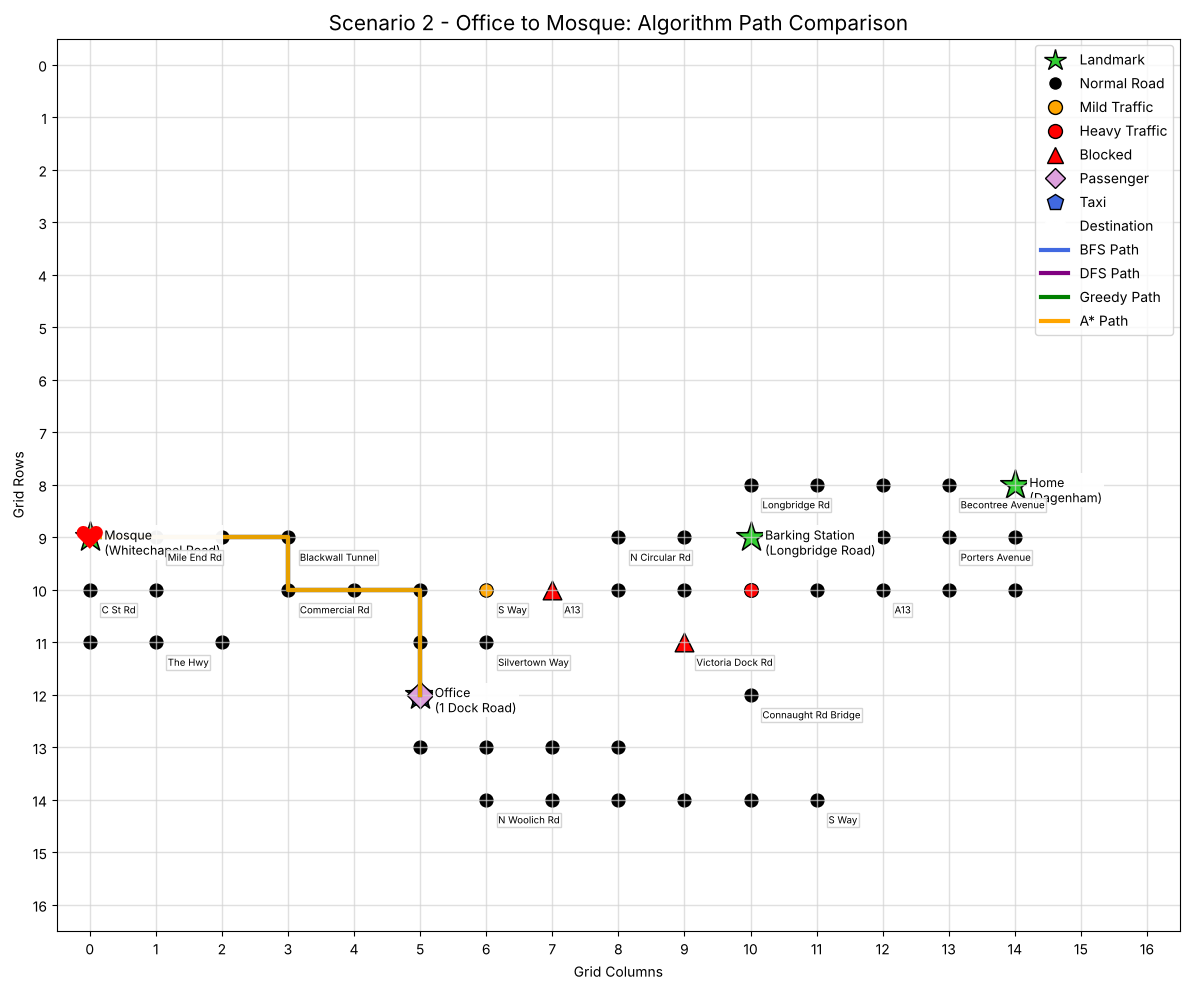

In [14]:
plot_scenario_with_all_algorithms(
    "Scenario 2 - Office to Mosque",
    scenarios["Scenario 2 - Office to Mosque"]
)

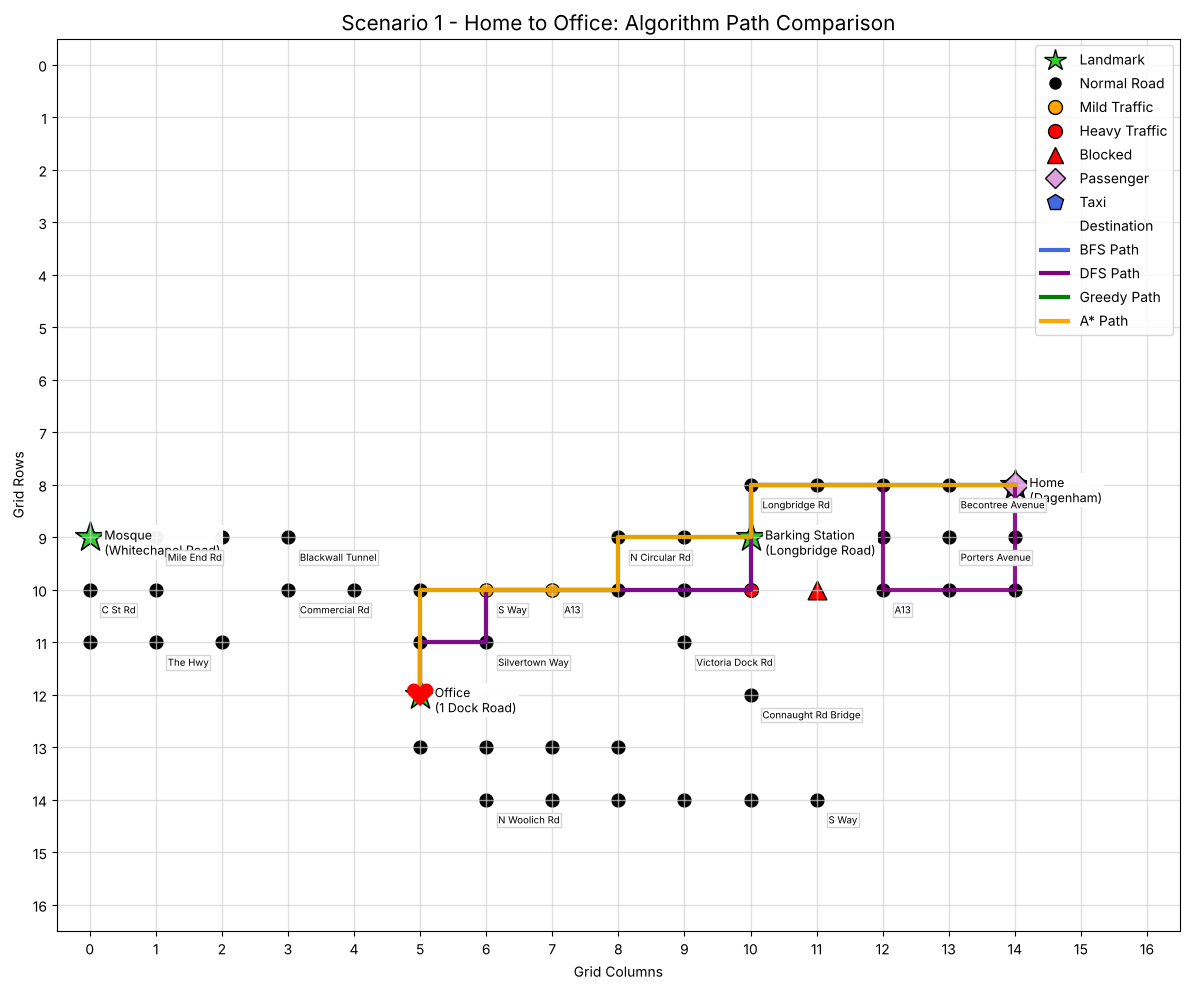

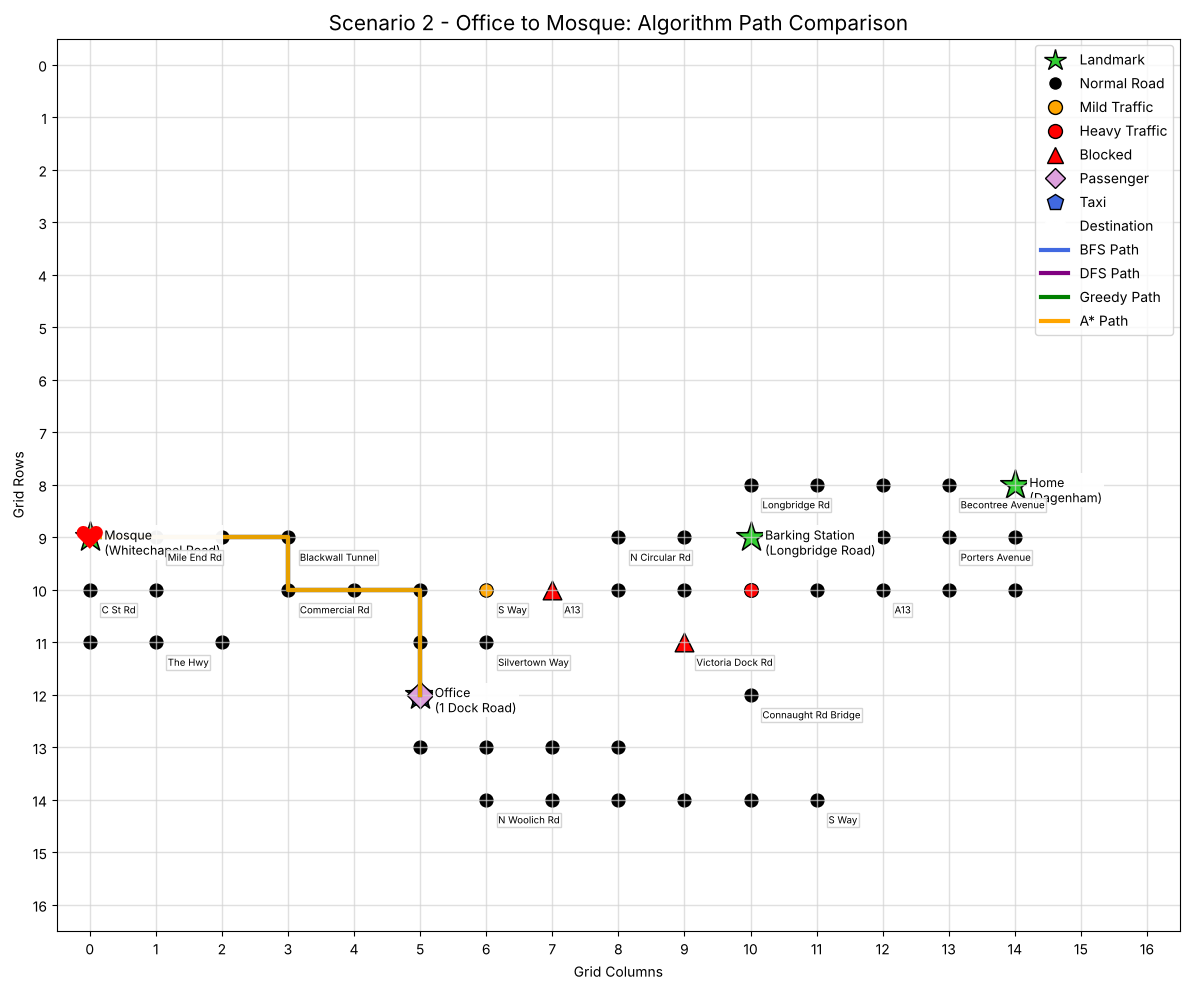

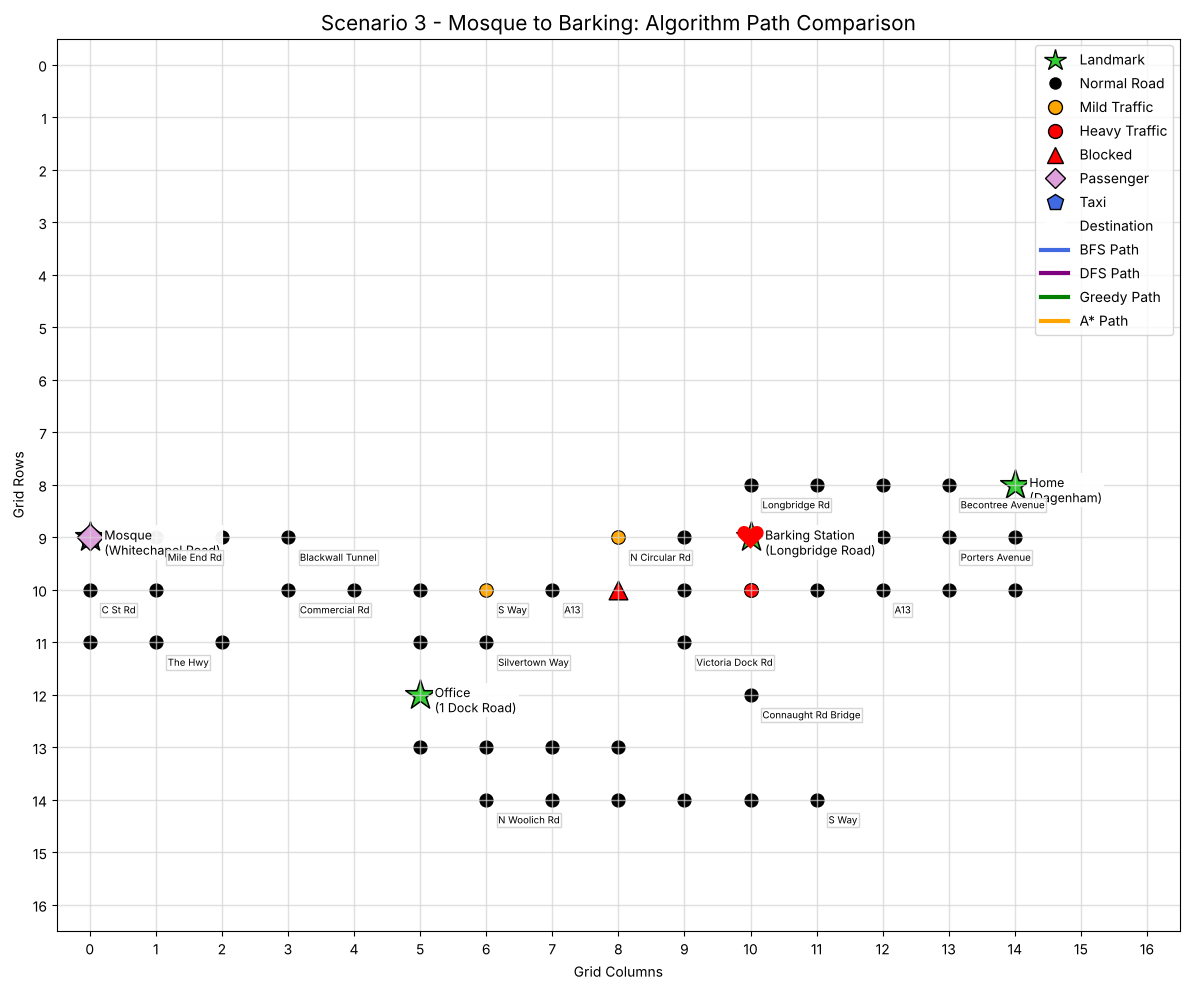

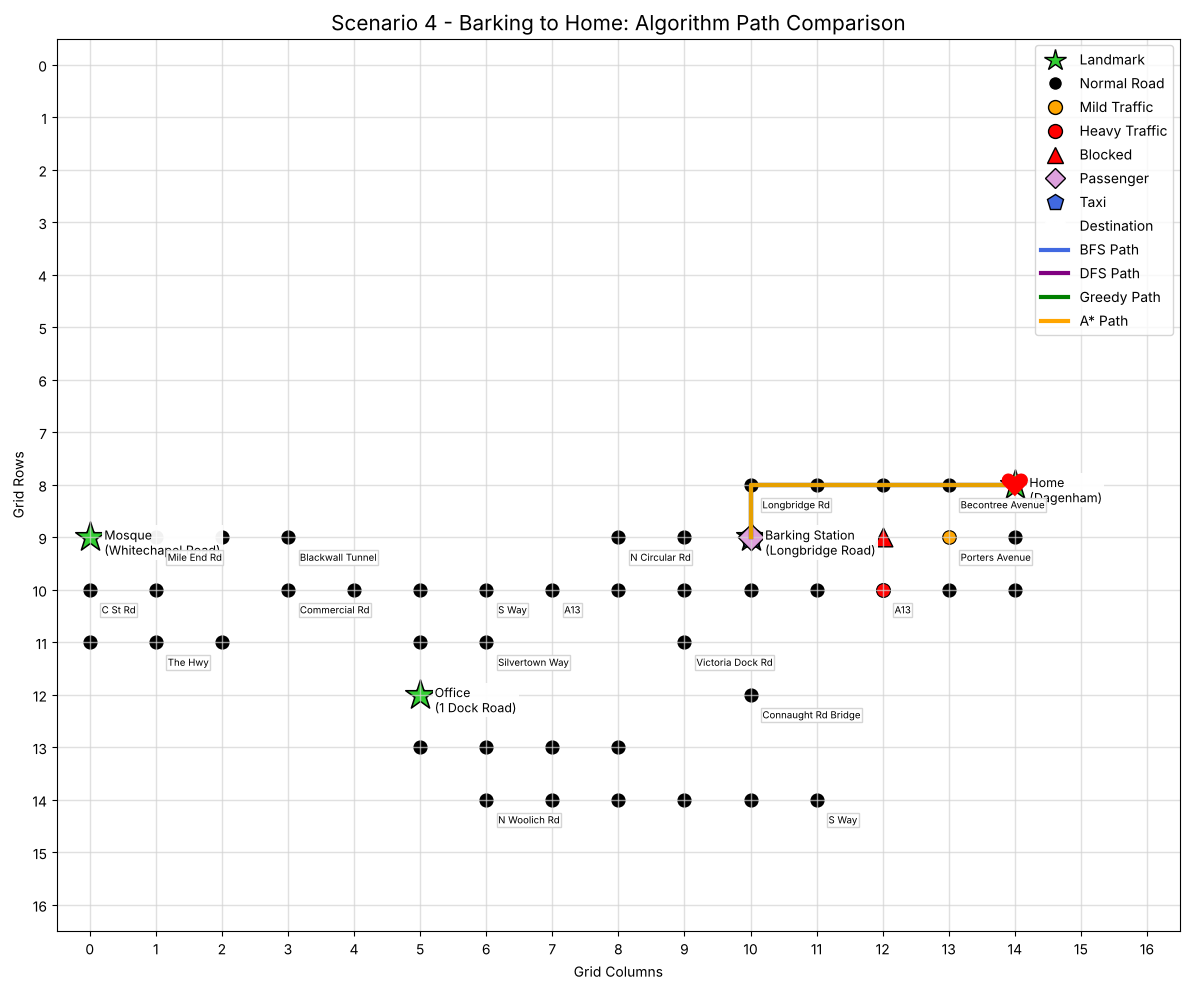

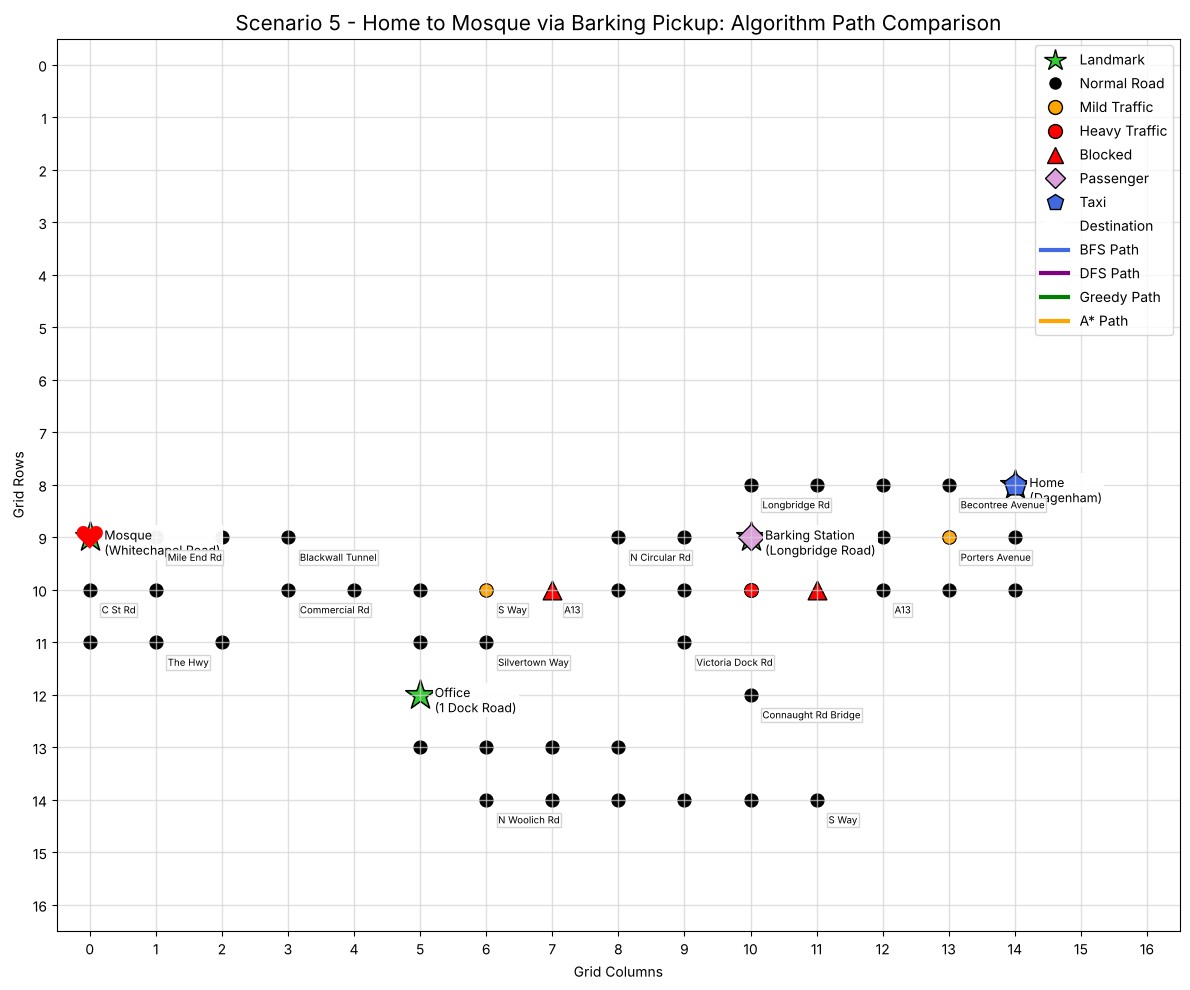

In [15]:
for scenario_name, scenario_data in scenarios.items():
    plot_scenario_with_all_algorithms(scenario_name, scenario_data)

## 10. Example Visual Run

The following cell visualises one scenario with its route, traffic, and blocked positions.

In [16]:
simulate_scenario("A*", "Scenario 5 - Home to Mosque via Barking Pickup", scenarios["Scenario 5 - Home to Mosque via Barking Pickup"], show_map=True)

{'Scenario': 'Scenario 5 - Home to Mosque via Barking Pickup',
 'Algorithm': 'A*',
 'Success': False,
 'Steps': 0,
 'Score': -20,
 'Nodes Explored': 24,
 'Path Cost': inf,
 'Path Length': 0}

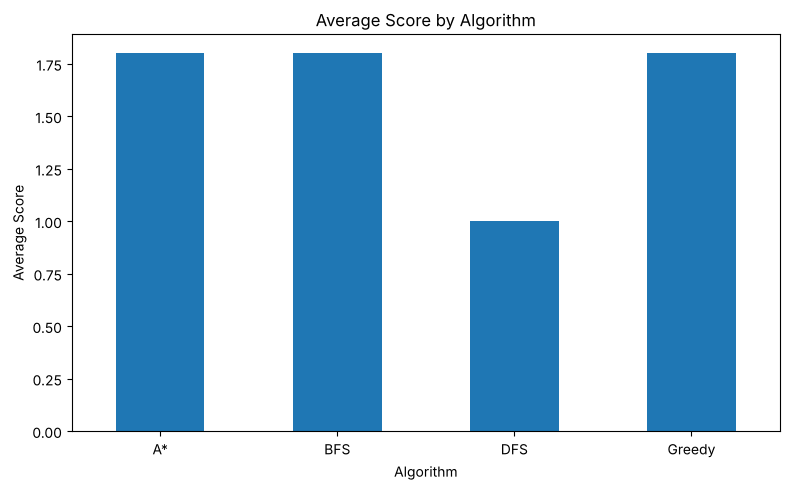

In [17]:
# quick chart
avg_score = results_df.groupby("Algorithm")["Score"].mean()

plt.figure(figsize=(8, 5))
avg_score.plot(kind="bar")
plt.title("Average Score by Algorithm")
plt.ylabel("Average Score")
plt.xlabel("Algorithm")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Discussion Notes

This environment supports several important observations:

- BFS is useful for unweighted shortest-path exploration, but it ignores traffic severity.
- DFS may produce valid paths but is less reliable and less efficient for structured road routing.
- Greedy search often appears direct, but may overlook better routes because it only follows heuristic closeness.
- A* is the most appropriate method for weighted traffic-aware routing because it combines movement cost and heuristic guidance.

The inclusion of mild and heavy traffic makes the environment more realistic than a purely open unweighted grid.